<h1 style="text-align:left;
           font-family:'Times New Roman', Arial, sans-serif;
           background: linear-gradient(45deg, #89f7fe, #1e3c72);
           -webkit-background-clip: text;
           -webkit-text-fill-color: transparent;
           font-size:38px;
           font-weight:700;">
A Finance Starter Kit
</h1>

## **Table of Contents**

- [Introduction](#introduction)
- [Data](#data)
  - Importing data from CSV files
  - Downloading financial data with *yfinance*
  - Downloading all S&P 500 tickers from Wikipedia
- [Pandas Series and DataFrames](#pandas-series-and-dataframes)
- [Returns](#returns)
  - Percentage and Log Returns
  - Data Selection with `.loc` and `.iloc`
- [Measures of Risk](#measures-of-risk)
  - Variance and Standard Deviation]
  - Annualized Returns
  - Annualized Volatility
  - Sharpe Ratio
- [Wealth Index](#wealth-index)
- [Drawdowns](#drawdowns)
  - Identifying Previous Peaks
  - Calculating Drawdowns
  - Visualizing Wealth, Peaks, and Drawdowns

### **Introduction**

This notebook introduces the fundamental Python tools and concepts used in **quantitative finance** and **data analysis**.  
It covers how to download, manipulate, and analyze financial time series using Python’s most popular libraries —  
**pandas**, **NumPy**, **Matplotlib**, and **yfinance**.  

Through a series of practical examples, the notebook demonstrates:
- How to fetch market data (e.g., stocks, indexes) from online sources.
- How to compute **returns**, **risk measures**, and **performance metrics**.
- How to visualize key financial concepts such as **Wealth Index**, **Volatility**, and **Drawdowns**.

This project serves as a foundation for anyone looking to build more advanced quantitative models,  
such as **GARCH volatility forecasting**, **portfolio optimization**, or **machine learning–based trading systems**.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

### **Data**

In [ ]:
# 1. Importing data from a CSV file, stored in the data folder
# pd.read_csv('data/name_of_the_file.csv')

In [3]:
# 2. Importing data using yfinance (AAPL)
import yfinance as yf
aapl = yf.download(tickers='AAPL', start='2020-01-01', end='2025-01-01')
aapl.head(3)

/var/folders/md/mwjcb61n2h39m_92tj88v3kc0000gn/T/ipykernel_2417/1460632216.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  aapl = yf.download(tickers='AAPL', start='2020-01-01', end='2025-01-01')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.538506,72.598884,71.292296,71.545882,135480400
2020-01-03,71.833298,72.594063,71.608692,71.765674,146322800
2020-01-06,72.405685,72.444328,70.703020,70.954195,118387200


In [ ]:
# For a better visualization
aapl.columns = aapl.columns.droplevel(1) # drop the column with repetition of the tickers
print(aapl.head(3))
print(aapl.tail(3))

Price           Close       High        Low       Open     Volume
Date                                                             
2020-01-02  72.538506  72.598884  71.292296  71.545882  135480400
2020-01-03  71.833298  72.594063  71.608692  71.765674  146322800
2020-01-06  72.405685  72.444328  70.703020  70.954195  118387200
Price            Close        High         Low        Open    Volume
Date                                                                
2024-12-27  254.685867  257.784882  252.164818  256.917934  42355300
2024-12-30  251.307861  252.603266  249.862994  251.337754  35557500
2024-12-31  249.534180  252.384064  248.547676  251.547039  39480700


In [5]:
# 3. Another example, if you want to download at the same time data for all the S&P 500 stocks, you can do:
import pandas_datareader.data as web
# Read the first HTML table from the Wikipedia page containing the S&P 500 companies.
# The 'storage_options' parameter adds a fake browser User-Agent to avoid HTTP 403 errors (Wikipedia blocks anonymous requests).
sp500 = pd.read_html("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies", storage_options={"User-Agent": "Mozilla/5.0"})[0]
sp500.head(10)

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999


In [6]:
# Replace dots in ticker symbols with dashes, since Yahoo Finance uses '-' instead of '.'
# Example: 'BRK.B' (Wikipedia format) -> 'BRK-B' (Yahoo Finance format)
sp500['Symbol'] = sp500['Symbol'].str.replace('.','-')

In [7]:
# Now:
# - Select the 'Symbol' column from the DataFrame sp500
# - '.unique()' -> removes any duplicated tickers (keeps only unique values)
# - '.tolist()' -> converts the NumPy array into a standard Python list
symbols_list = sp500['Symbol'].unique().tolist()
# We can't use 'head()': with a list we use this:
symbols_list[:10]

['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']

In [8]:
# Downloading the data for all the stocks in the S&P 500
# Another interesting thing: if you want to download data for the previous 10 years, starting from a given end date
import datetime as dt
END_DATE = '2025-01-01'
START_DATE = pd.to_datetime(END_DATE) - pd.DateOffset(365 * 10)
df = yf.download(tickers=symbols_list, start=START_DATE, end=END_DATE).stack() # Stack the DataFrame for better visualization (multi-index format)
df.index.names = ['date', 'ticker']
df.columns = df.columns.str.lower() # Convert all column names to lowercase
df

/var/folders/md/mwjcb61n2h39m_92tj88v3kc0000gn/T/ipykernel_2417/1731951176.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(tickers=symbols_list, start=START_DATE, end=END_DATE).stack() # Stack the DataFrame for better visualization (multi-index format)
[*********************100%***********************]  503 of 503 completed

2 Failed downloads:
['SOLS', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2015-01-04 00:00:00 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1420347600, endDate = 1735707600")')
/var/folders/md/mwjcb61n2h39m_92tj88v3kc0000gn/T/ipykernel_2417/1731951176.py:6: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df = yf.download(tickers=symbols_list, start=START_DAT

Price              adj close       close        high         low        open  \
date       ticker                                                              
2015-01-05 A             NaN   36.425392   37.029431   36.333872   36.901302   
           AAPL          NaN   23.577576   24.110152   23.391175   24.030265   
           ABBV          NaN   41.299294   42.225571   40.807407   41.842284   
           ABT           NaN   36.426785   36.824228   36.199676   36.337562   
           ACGL          NaN   18.428413   18.542522   18.384038   18.441093   
...                      ...         ...         ...         ...         ...   
2024-12-31 XYZ           NaN   84.989998   88.000000   84.820000   87.720001   
           YUM           NaN  132.235291  132.856242  131.338342  132.166288   
           ZBH           NaN  104.874809  105.738592  104.209601  105.152814   
           ZBRA          NaN  386.220001  387.410004  381.750000  383.420013   
           ZTS           NaN  160.793213  161.602466  159.747117  160.763608   

Price                   volume  
date       ticker               
2015-01-05 A         2041800.0  
           AAPL    257142000.0  
           ABBV      8007400.0  
           ABT       5735900.0  
           ACGL      1095900.0  
...                        ...  
2024-12-31 XYZ       4989400.0  
           YUM       1217100.0  
           ZBH        683300.0  
           ZBRA       327900.0  
           ZTS       1327400.0  

[1219224 rows x 6 columns]

In [9]:
# Save the data in a CSV file
df.to_csv('sp500.csv')

### **Pandas Series and DataFrames**

In **pandas**, data is organized primarily in two key structures: **Series** and **DataFrames**.

#### 🧩 **Series**
A **Series** is a one-dimensional labeled array that can hold data of any type — integers, floats, strings, etc.  
It has two main components:
- **Values**: the actual data.
- **Index**: labels that identify each value.

In [10]:
# Example
s = pd.Series([10, 20, 30], index=['A', 'B', 'C'])
print(s)

A    10
B    20
C    30
dtype: int64


#### 🧱 **DataFrame**

A **DataFrame** is a two-dimensional labeled data structure — like a table in Excel —
where each column is a Series and all columns share the same index.

In [11]:
# Example
data = {'Price':[10, 20, 30], 
        'Quantity':[5, 3, 8]}

dataframe = pd.DataFrame(data, index=['A', 'B', 'C'])
print(dataframe)

   Price  Quantity
A     10         5
B     20         3
C     30         8


In [12]:
print(type(aapl))
print(type(aapl['Close']))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


**dropna()** -> is a pandas method used to drop (delete) rows or columns with missing data.  
**inplace=True** -> means that the operation is performed directly on the original DataFrame, without creating a new one.

In [ ]:
# You can read the data from the CSV file
df = pd.read_csv('sp500.csv')
df

,date,ticker,adj close,close,high,low,open,volume
0,2015-01-05,A,NaN,36.425392,37.029431,36.333872,36.901302,2041800.0
1,2015-01-05,AAPL,NaN,23.577576,24.110152,23.391175,24.030265,257142000.0
2,2015-01-05,ABBV,NaN,41.299294,42.225571,40.807407,41.842284,8007400.0
3,2015-01-05,ABT,NaN,36.426785,36.824228,36.199676,36.337562,5735900.0
4,2015-01-05,ACGL,NaN,18.428413,18.542522,18.384038,18.441093,1095900.0
...,...,...,...,...,...,...,...,...
1219219,2024-12-31,XYZ,NaN,84.989998,88.000000,84.820000,87.720001,4989400.0
1219220,2024-12-31,YUM,NaN,132.235291,132.856242,131.338342,132.166288,1217100.0
1219221,2024-12-31,ZBH,NaN,104.874809,105.738592,104.209601,105.152814,683300.0
1219222,2024-12-31,ZBRA,NaN,386.220001,387.410004,381.750000,383.420013,327900.0


In [14]:
type(df)

pandas.core.frame.DataFrame

### **Returns**

In [ ]:
# Percentage returns: r_t = (P_t / P_{t-1}) - 1
aapl['ret_pct'] = aapl['Close'].pct_change()

# Log returns: r_t = ln(P_t) - ln(P_{t-1})
aapl['ret_log'] = np.log(aapl['Close']).diff()

# Dropping NA values
aapl = aapl.dropna()

aapl.head(5)

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2020-01-03,71.833298,72.594063,71.608692,71.765674,146322800,-0.009722,-0.009769
2020-01-06,72.405685,72.444328,70.703020,70.954195,118387200,0.007968,0.007937
2020-01-07,72.065132,72.671325,71.845354,72.415322,108872000,-0.004703,-0.004715
2020-01-08,73.224434,73.526326,71.768109,71.768109,132079200,0.016087,0.015959
2020-01-09,74.779747,74.972955,73.951358,74.202527,170108400,0.021240,0.021018


Text(0, 0.5, 'Daily Returns (%)')

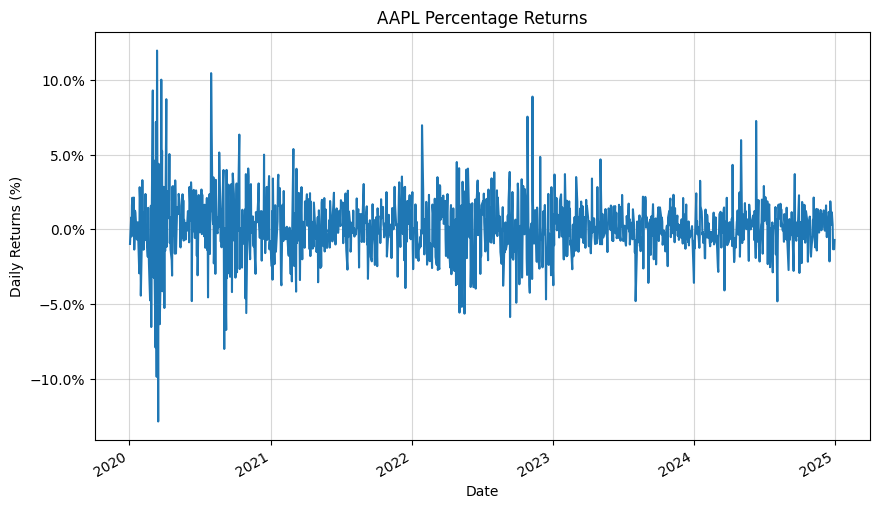

In [16]:
import matplotlib.ticker as mtick

aapl['ret_pct'].plot(title='AAPL Percentage Returns', figsize=(10, 6))
plt.grid(alpha=0.5)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Date')
plt.ylabel('Daily Returns (%)')

In [17]:
# Using only [], we get ret_pct as a Series
ret_pct = aapl['ret_pct']
ret_pct.head(5)

Date
2020-01-03   -0.009722
2020-01-06    0.007968
2020-01-07   -0.004703
2020-01-08    0.016087
2020-01-09    0.021240
Name: ret_pct, dtype: float64

In [18]:
ret_pct.describe().round(4)

count    1257.0000
mean        0.0012
std         0.0200
min        -0.1286
25%        -0.0084
50%         0.0012
75%         0.0120
max         0.1198
Name: ret_pct, dtype: float64

In [19]:
# Otherwise, using double [[]], we get a DataFrame
ret_log = aapl[['ret_log']]
ret_log.head(5)

Price,ret_log
Date,
2020-01-03,-0.009769
2020-01-06,0.007937
2020-01-07,-0.004715
2020-01-08,0.015959
2020-01-09,0.021018


In [20]:
# Another example
returns_df = aapl[['ret_pct', 'ret_log']]
returns_df.head(5)

Price,ret_pct,ret_log
Date,,
2020-01-03,-0.009722,-0.009769
2020-01-06,0.007968,0.007937
2020-01-07,-0.004703,-0.004715
2020-01-08,0.016087,0.015959
2020-01-09,0.021240,0.021018


In [21]:
# We can use .loc and .iloc to filter data:
# -> .loc for a label-based indexing
# -> .iloc for a position-based indexing
print(f'This is the .loc:\n', aapl.loc['2021-01-04'])  # Data for a specific date
print(f'\nThis is the .iloc:\n', aapl.iloc[5])         # The 5th row

This is the .loc:
 Price
Close      1.260966e+02
High       1.301890e+02
Low        1.235144e+02
Open       1.301013e+02
Volume     1.433019e+08
ret_pct   -2.471930e-02
ret_log   -2.502995e-02
Name: 2021-01-04 00:00:00, dtype: float64

This is the .iloc:
 Price
Close      7.494882e+01
High       7.551397e+01
Low        7.444648e+01
Open       7.501404e+01
Volume     1.406448e+08
ret_pct    2.260973e-03
ret_log    2.258421e-03
Name: 2020-01-10 00:00:00, dtype: float64


In [22]:
# Both .loc and .iloc can be used for slicing, if you want to select a range of rows or columns
# For example:
aapl.loc['2021-01-04':'2021-01-10']  # Slicing rows by date range'

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2021-01-04,126.096581,130.189040,123.514430,130.101348,143301900,-0.024719,-0.025030
2021-01-05,127.655594,128.366914,125.141651,125.589879,97664900,0.012364,0.012288
2021-01-06,123.358528,127.694595,123.144160,124.449854,155088000,-0.033661,-0.034241
2021-01-07,127.567902,128.259729,124.586253,125.073451,109578200,0.034123,0.033554
2021-01-08,128.668991,129.234143,126.895583,129.039251,105158200,0.008631,0.008594


In [23]:
aapl.iloc[5:10]                    # Slicing rows by position

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2020-01-10,74.948822,75.513970,74.446478,75.014035,140644800,0.002261,0.002258
2020-01-13,76.550041,76.576611,75.146850,75.265196,121532000,0.021364,0.021139
2020-01-14,75.516373,76.697376,75.393206,76.487261,161954400,-0.013503,-0.013595
2020-01-15,75.192726,76.197422,74.760415,75.315900,121923600,-0.004286,-0.004295
2020-01-16,76.134644,76.245745,75.373878,75.736148,108829200,0.012527,0.012449


### **Measures of Risk**

**Variance**

$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (R_i - \mu)^2$

**Standard Deviation**

$\sigma = \sqrt{\sigma^2}$

*Standard Deviation is the square root of the variance.*

In [ ]:
std = ret_log.std() # Standard Deviation
print(f'Standard Deviation: {std.iloc[0]:.4%}')

Standard Deviation: 1.9940%


### **Annualized Returns**
For daily returns, the compound annualized return can be calculated using the formula:
${R}_{annualized} = (1 + {r}_{d})^{252} - 1$, or in general terms: $R_{\text{annualized}} = \left( \prod_{i=1}^{N} (1 + r_i) \right)^{\frac{252}{N}} - 1$

In [25]:
def annualized_returns(r, periods_per_year=252):
    """
    Annualized returns based on the data frequency.
    
    Parameters:
    -> r: pandas Series or DataFrame
       Series of returns (daily, monthly, etc.)
    -> periods_per_year: int, default=252
       Number of periods in a year (252 for daily data, 12 for monthly data, etc.)
    """
    n_periods = r.shape[0]
    compounded_growth = (1+r).prod()
    return compounded_growth ** (periods_per_year / n_periods) - 1

In [58]:
ann_ret = annualized_returns(ret_pct)
print(f'Annualized Return: {ann_ret:.4%}')

Annualized Return: 28.1057%


### **Annualized Volatility**
The annualized volatility can be calculated using the formula:
$\sigma_{\text{annualized}} = \sigma_d \times \sqrt{252}$.  
Let's compute a function to do this:

In [27]:
def annualized_volatility(r, periods_per_year=252):
    return r.std() * np.sqrt(periods_per_year)

In [59]:
ann_vol = annualized_volatility(ret_pct)
print(f'Annualized Volatility: {ann_vol:.4%}')

Annualized Volatility: 31.6786%


### **Raw Sharpe Ratio**
Sharpe Ratio is a measure of risk-adjusted return, calculated as the ratio of the excess return of an investment to its standard deviation (volatility).  
The formula for the Sharpe Ratio is:
$S = \frac{R_p - R_f}{\sigma_p}$.  
Otherwise, we can calculate it using $\textit{annualized returns}$ and $\textit{annualized volatility}$ as follows:


In [61]:
# Raw Sharpe Ratio
sharpe_ratio = ann_ret / ann_vol
print(f'Sharpe Ratio: {sharpe_ratio:.4f}')

Sharpe Ratio: 0.8872


### **Wealth Index**

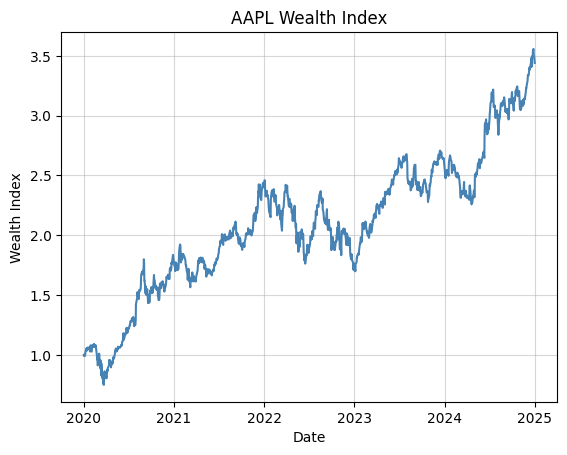

In [62]:
wealth_index = (1 + ret_pct).cumprod()
start_date = wealth_index.index.min() - pd.DateOffset(1)
wealth_index = pd.concat([pd.Series([1], index=[start_date]), wealth_index])
plt.plot(wealth_index, color='steelblue')
plt.title('AAPL Wealth Index')
plt.xlabel('Date')
plt.ylabel('Wealth Index')
plt.grid(alpha=0.5)

### **Drawdowns**
First of all, let's define $\textit{Drawdowns}$: this is the return from the previous peak to the present value.  
Therefore, we can find the previous peak using this method:

In [63]:
previous_peaks = wealth_index.cummax()
# .cummax() is just a cumulative maximum function, which will set each value equal to the highest data point on or before each respective date.

In [64]:
# Now, we can calculate the drawdowns as follows:
drawdowns = (wealth_index - previous_peaks) / previous_peaks
drawdowns.head(10)

2020-01-02    0.000000
2020-01-03   -0.009722
2020-01-06   -0.001831
2020-01-07   -0.006526
2020-01-08    0.000000
2020-01-09    0.000000
2020-01-10    0.000000
2020-01-13    0.000000
2020-01-14   -0.013503
2020-01-15   -0.017731
dtype: float64

In [65]:
max_drawdown = drawdowns.min()
max_drawdown_date = drawdowns.idxmin()
print(f"Max Drawdown: {max_drawdown:.2%} on {max_drawdown_date.date()}")

Max Drawdown: -31.43% on 2020-03-23


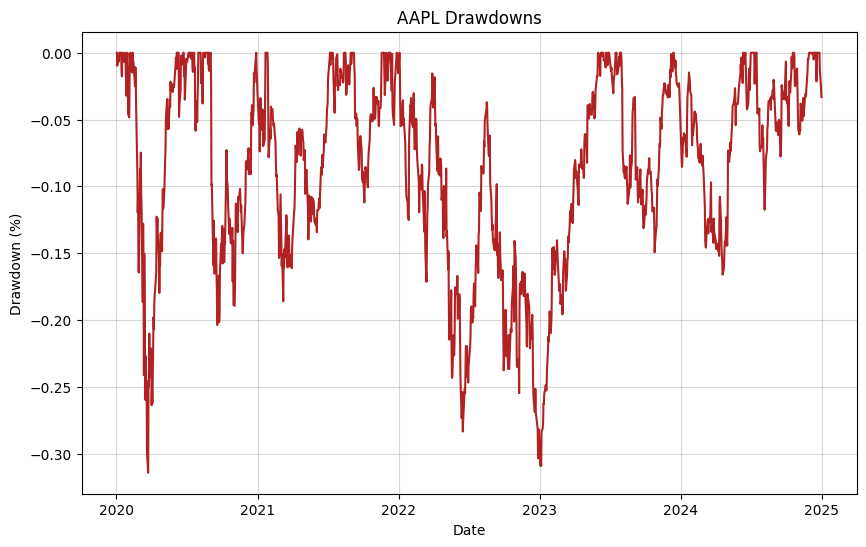

In [70]:
# Plotting the drawdowns
plt.figure(figsize=(10, 6))
plt.plot(drawdowns, color='firebrick')
plt.title('AAPL Drawdowns')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.grid(alpha=0.5)
plt.show()

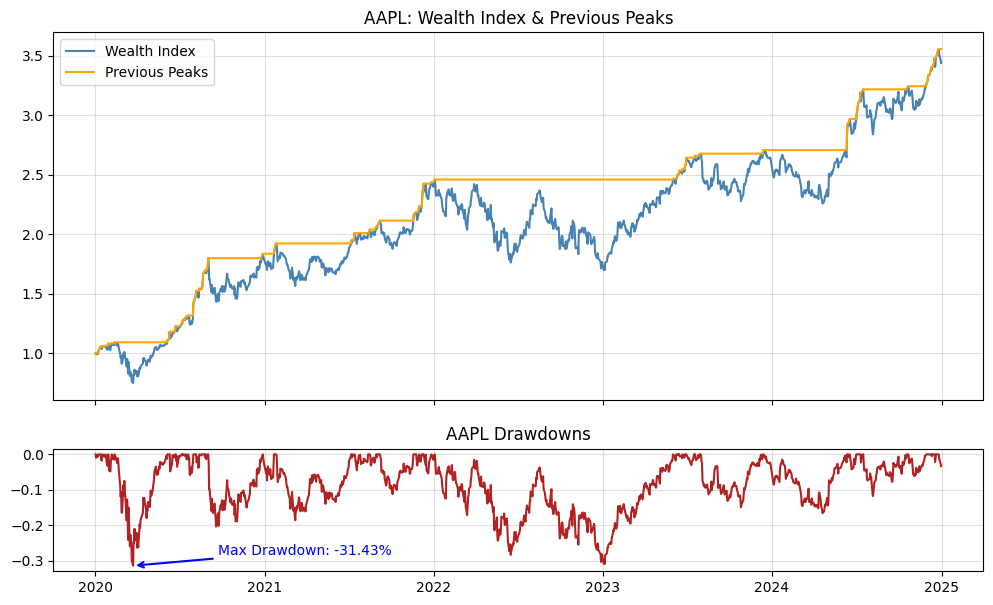

In [76]:
# Plotting wealth index, previous peaks, and drawdowns
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(wealth_index, label="Wealth Index", color="steelblue")
ax1.plot(previous_peaks, label="Previous Peaks", color="orange")
ax1.set_title("AAPL: Wealth Index & Previous Peaks")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.4)

ax2.plot(drawdowns, color="firebrick")
ax2.set_title("AAPL Drawdowns")
ax2.grid(alpha=0.4)

# Annotate max drawdown on the wealth index plot
max_dd = drawdowns.min()
max_dd_date = drawdowns.idxmin()
ax2.annotate(f"Max Drawdown: {max_dd:.2%}",
             xy=(max_dd_date, max_dd), # point to annotate
             xytext=(max_dd_date + pd.DateOffset(months=6), max_dd*0.9), # text position: 'months=6' moves the text 6 months to the right, 0.9 moves it 10% up from the drawdown value
             arrowprops=dict(arrowstyle="->", lw=1.5, color="blue"),
             color="blue")
plt.show()